## Abstract

Placeholder. Write this last, in 280 characters or fewer. The framing depends on how Question 3 resolves.

----

:::{.callout-note title="AI usage disclosure" collapse="true"}
This is a placeholder for the AI usage disclosure. Once all authors sign the AI code form on AirTable, SlackBot will message you an AI disclosure that you should place here.
:::

:::{.callout-important title="This notebook is a scaffold"}
Most prose below is a placeholder: section headers and a note on what the section will argue. The campaigns have run and their tables are in `data/campaigns/`, so the numbers exist, but the narrative has not been written against them. The experiments that settle Question 3 have not run.
:::

## Purpose

Placeholder. This section will state why the work was done, the key takeaway, and who it is for.

The argument to make here: binder design campaigns run with ESMFold2 return mostly &alpha;-helical binders, and a designer who needs a different fold has no obvious knob to turn. We add a secondary-structure term to the design loss, show what it buys and what it costs, and report whether the resulting designs are worth trialing.

Primary audience: people running structure-prediction-based binder design campaigns, and people interested in what can be steered in a folding model after training.

## Introduction

Placeholder. Three claims to establish, each needing citations added to `ref.bib`:

1. **Binder design tends to be &alpha;-rich.** Design pipelines built on structure predictors return helical binders far more often than any other fold class. To write: how general this is across pipelines, and what is already known about why.
2. **Increasing structural diversity yields better campaigns.** A more structurally diverse design pool improves the odds that a campaign yields a binder that works experimentally. To write: the evidence for this, and how diversity is usually pursued today.
3. **Sometimes success is locked behind &beta;-rich designs.** Some epitopes are not addressable by a helical bundle. To write: concrete examples where a &beta;-rich binder was the one that worked.

These three claims motivate the three questions that structure the rest of the notebook.

## Reproducing this notebook

Placeholder. Design campaigns in this pub require GPU inference and hours of compute, so the notebook will read precomputed artifacts rather than recompute them, following the pattern used in [our MSA Pairformer pub](https://github.com/Arcadia-Science/2025-phylogenetic-analysis-of-msa-pairformer): a small `DataArtifact` helper in `src/analysis/` that downloads each archive into `data/` on first execution, trying a public S3 bucket first and falling back to the Zenodo record.

Nothing to download yet. The archives do not exist, the S3 bucket has not been created, and the Zenodo record has not been minted, so the cell below is an empty stub. When the artifacts are ready, this section needs:

- a `DataArtifact` implementation in `src/analysis/`, with the S3 bucket name and Zenodo record ID,
- an `INPUT_DATA_ARCHIVES` mapping for the campaign manifests, per-design secondary-structure tables, per-step traces, critic PDB structures, and the RCSB reference set,
- an `INTERMEDIATE_DATA_ARCHIVES` mapping with per-artifact `fetch` toggles for anything a reader could recompute given a GPU.

In [1]:
import warnings

import pandas as pd
from analysis import (
    artifacts,
    campaign,
    composition,
    figures,
    paths,
    reference,
    secondary_structure,
    targets,
)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
paths.ensure_dirs()

TARGETS = list(targets.TARGET_SPECS)
ARMS = list(targets.CAMPAIGN_ARMS)

artifacts.status_table(TARGETS, ARMS)

,target,arm,results present (bool),summary present (bool),manifest present (bool),predicted complexes (count),loss log present (bool),analysable (bool)
0,egfr_d3,vanilla,True,True,True,30,True,True
1,egfr_d3,helix_logcap_w02,True,True,True,30,True,True
2,egfr_d3,helix_logcap_w05,True,True,True,30,True,True
3,pdgfrb_d2d3,vanilla,True,True,True,30,True,True
4,pdgfrb_d2d3,helix_logcap_w02,True,True,True,30,True,True
5,pdgfrb_d2d3,helix_logcap_w05,True,True,True,30,True,True
6,pdl1_igv,vanilla,True,True,True,30,True,True
7,pdl1_igv,helix_logcap_w02,True,True,True,30,True,True
8,pdl1_igv,helix_logcap_w05,True,True,True,30,True,True
9,ctla4_igv,vanilla,True,True,True,30,True,True


### Generating the campaigns yourself

Every figure below reads small tables from `data/campaigns/`, which are tracked in this repository, so the notebook renders from a fresh clone with no GPU and no download.

Regenerating those tables is opt-in, because it costs real GPU time and because **it will not reproduce these designs**. The design loop is not seed-reproducible: across two runs of an identically configured arm, no seed reproduced its own result and per-seed interface pTM moved by 0.14 to 0.20. What a rerun reproduces is the *conclusions*, which is the claim worth checking.

To regenerate, set `USE_MODAL=1` and execute:

```bash
USE_MODAL=1 make execute
```

The cell below then deploys nothing and downloads nothing; it looks at which composition tables are missing, launches only those on [Modal](https://modal.com), waits, and collects them. You need a Modal account and a deployed app:

```bash
modal deploy src/analysis/modal_app.py
```

The full grid is six targets by three arms by thirty seeds, which is 540 designs at 150 optimization steps each. `ESMFOLD2_SS_MAX_CONTAINERS` sets how many run at once and defaults to 30; at that concurrency the grid takes a couple of hours, and at Modal's default quota of a few GPUs it takes most of a day. Set it to match your workspace rather than the number here.

With `USE_MODAL` unset the cell reports what is on disk and does nothing else, which is what happens on every render that is not deliberately paying for compute.

In [2]:
if campaign.use_modal():
    status = campaign.ensure(TARGETS, ARMS)
else:
    status = artifacts.status_table(TARGETS, ARMS)
    absent = artifacts.missing(TARGETS, ARMS)
    print(f"{campaign.USE_MODAL_ENV} is not set, so nothing was generated.")
    print(f"{len(absent)} of {len(TARGETS) * len(ARMS)} campaigns have no results.")

status

USE_MODAL is not set, so nothing was generated.
0 of 15 campaigns have no results.


,target,arm,results present (bool),summary present (bool),manifest present (bool),predicted complexes (count),loss log present (bool),analysable (bool)
0,egfr_d3,vanilla,True,True,True,30,True,True
1,egfr_d3,helix_logcap_w02,True,True,True,30,True,True
2,egfr_d3,helix_logcap_w05,True,True,True,30,True,True
3,pdgfrb_d2d3,vanilla,True,True,True,30,True,True
4,pdgfrb_d2d3,helix_logcap_w02,True,True,True,30,True,True
5,pdgfrb_d2d3,helix_logcap_w05,True,True,True,30,True,True
6,pdl1_igv,vanilla,True,True,True,30,True,True
7,pdl1_igv,helix_logcap_w02,True,True,True,30,True,True
8,pdl1_igv,helix_logcap_w05,True,True,True,30,True,True
9,ctla4_igv,vanilla,True,True,True,30,True,True


## Question 1: What is ESMFold2's basal &alpha;-richness?

Placeholder. The answer to establish here is that it is quite high: an unsteered campaign produces designs whose residues are predominantly helical, with sheet content near zero for most designs.

What this section will do:

- Define how secondary structure is assigned. Kabsch&ndash;Sander labels from [`pydssp`](https://github.com/ShintaroMinami/PyDSSP) applied to the critic-predicted complex, collapsed to helix / sheet / coil fractions per binder.
- Report the distribution of per-design helix, sheet, and coil fraction (fraction of binder residues, 0&ndash;1) for the unsteered campaign.
- State the campaign setup that all later arms are compared against: same target, same ensemble, same seed range, same number of designs.

Figure 1 goes in the cell below: distributions of per-design helix, sheet, and coil fraction (fraction of binder residues, 0&ndash;1) for the unsteered campaign.

Vanilla campaigns with composition tables: 5 of 5
  egfr_d3
  pdgfrb_d2d3
  pdl1_igv
  ctla4_igv
  cd45_d3d4


,"natural binders, length-matched (%)",ESMFold2 vanilla designs (%)
mean helix,36.6,66.5
mean sheet,23.2,12.8
designs with zero sheet,21.4,70.0


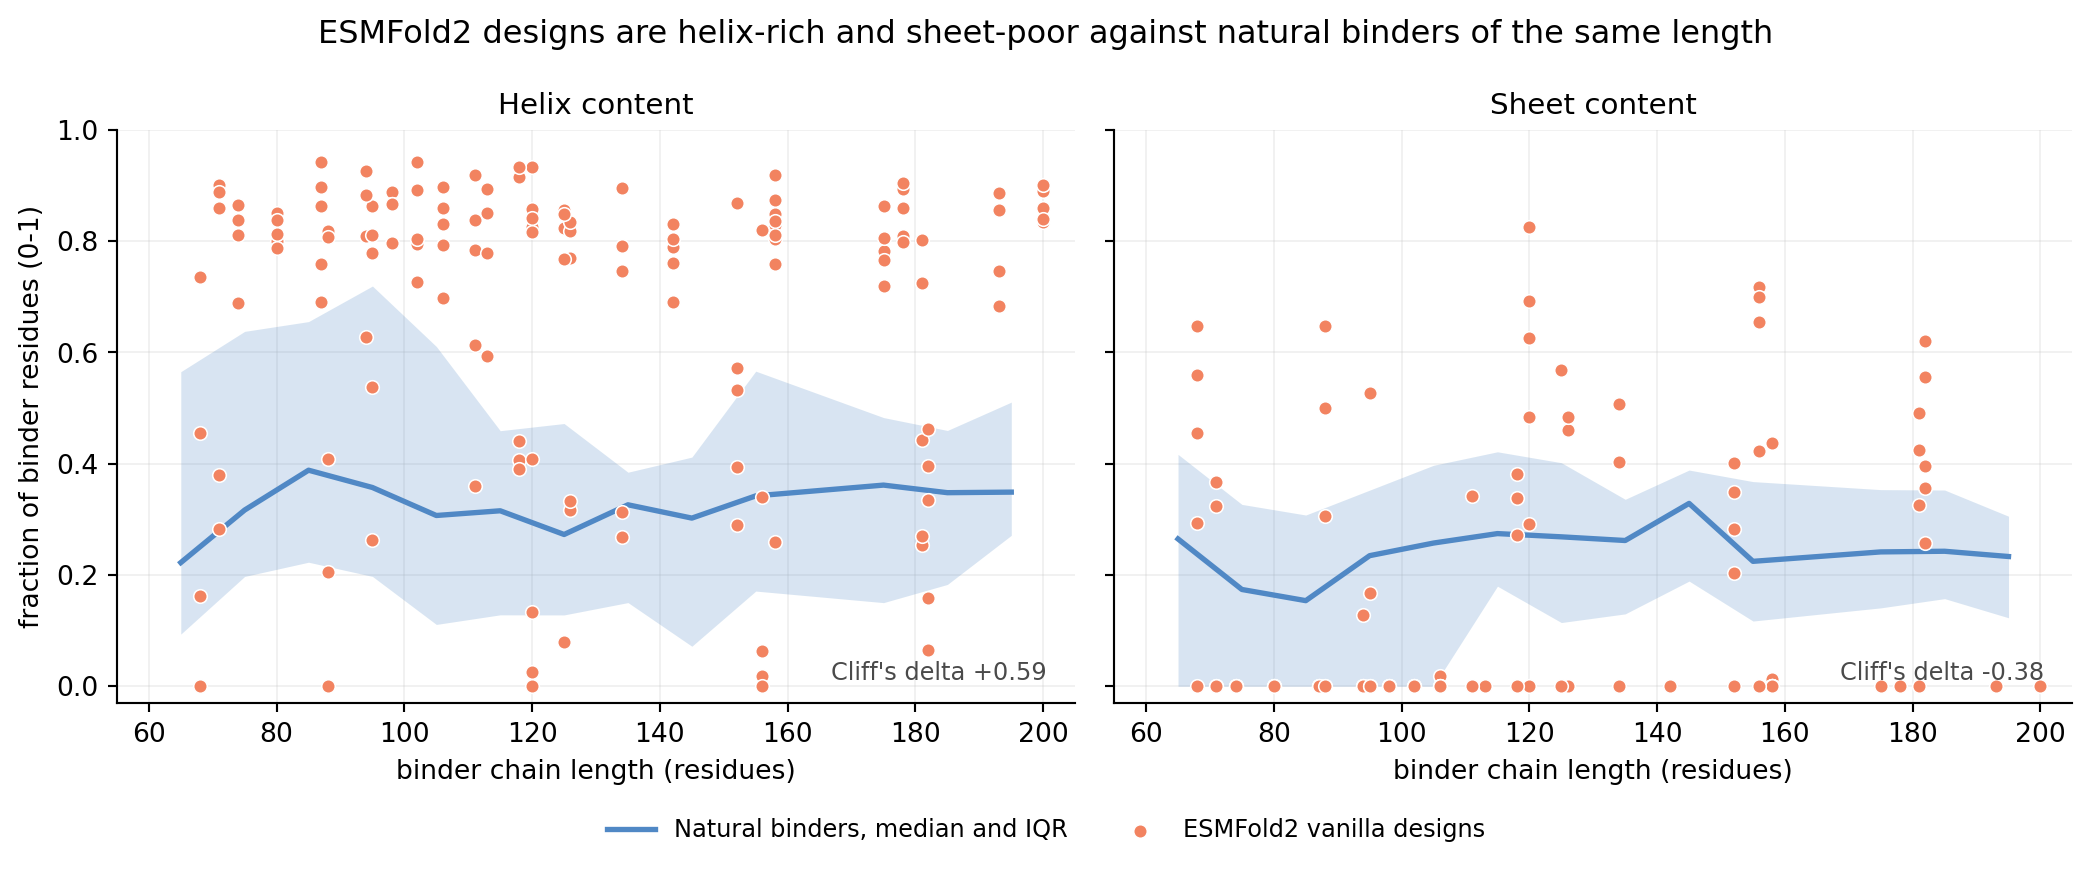

In [3]:
ready = composition.available(TARGETS, ["vanilla"])
print(f"Vanilla campaigns with composition tables: {len(ready)} of {len(TARGETS)}")
for key, _ in ready:
    print(f"  {key}")
awaiting = [t for t in TARGETS if (t, "vanilla") not in ready]
if awaiting:
    print(f"Awaiting: {', '.join(awaiting)}")

if not reference.is_available():
    reference.fetch(reference.COMPOSITION_TABLE)

natural = reference.composition()
designs = composition.load_all([t for t, _ in ready], ["vanilla"])
matched = reference.length_matched(
    natural, designs["binder length (residues)"], "binder_sample_length_residues"
)

summary = pd.DataFrame(
    {
        "natural binders, length-matched (%)": [
            100 * matched["binder_helix_fraction"].mean(),
            100 * matched["binder_sheet_fraction"].mean(),
            100 * (matched["binder_sheet_fraction"] == 0).mean(),
        ],
        "ESMFold2 vanilla designs (%)": [
            100 * designs["helix (fraction 0-1)"].mean(),
            100 * designs["sheet (fraction 0-1)"].mean(),
            100 * (designs["sheet (fraction 0-1)"] == 0).mean(),
        ],
    },
    index=["mean helix", "mean sheet", "designs with zero sheet"],
).round(1)
display(summary)

fig = figures.composition_vs_length(matched, designs)

Placeholder. A short paragraph reading off the figure, then a sentence on why a helix-dominated pool is a problem for a campaign, which sets up Question 2.

A judgement call to make while writing: whether to frame the high &alpha;-richness as evidence of model bias here, or to defer that entirely to Question 3. The outline defers it, and this scaffold follows the outline.

## Question 2: Can we steer designs away from the &alpha;-rich basin?

Placeholder. The answer to establish here is yes, with a cost: helix content drops sharply, sheet and coil content rise, and interface confidence (ipTM) gets worse.

### How ESMFold2 designs a binder

Placeholder. Before the loss term can be explained, this section needs a compact description of the design algorithm:

- the target and the binder length,
- optimization over the binder's sequence representation by gradient descent through the folding model,
- the loss the vanilla campaign optimizes, and the confidence critic used to score the finished complex,
- how many steps a design runs for, and what is held fixed across arms.

A schematic (Figure 2) would earn its place here. Decide whether to draw one or to describe the loop in prose.

In [4]:
rows = []
for key in TARGETS:
    spec = targets.target(key)
    comp = secondary_structure.structure_composition(
        spec.structure_path, spec.chain, (spec.crop_start, spec.crop_end)
    )
    rows.append(
        {
            "target": spec.key,
            "protein": spec.protein,
            "construct (UniProt)": spec.construct_uniprot,
            "construct length (residues)": spec.construct_length,
            "resolution (Angstrom)": spec.resolution_angstrom,
            "target helix (%)": round(comp.helix_percent, 1),
            "target sheet (%)": round(comp.sheet_percent, 1),
            "target coil (%)": round(comp.coil_percent, 1),
        }
    )
pd.DataFrame(rows)

,target,protein,construct (UniProt),construct length (residues),resolution (Angstrom),target helix (%),target sheet (%),target coil (%)
0,egfr_d3,Human EGFR domain III,334-524,191,2.61,18.3,22.6,59.1
1,pdgfrb_d2d3,Human PDGFRB Ig-C2 domains 2-3,126-312,187,2.30,2.1,48.1,49.7
2,pdl1_igv,Human PD-L1 IgV domain,18-132,115,2.45,13.0,47.0,40.0
3,ctla4_igv,Human CTLA-4 IgV domain,38-155,118,1.80,2.5,52.5,44.9
4,cd45_d3d4,Human CD45 FN3 domains d3-d4,390-574,185,2.90,0.0,50.5,49.5


### The secondary-structure loss term

Placeholder. This section introduces the term added to the design loss: a capped logarithmic penalty on helical i&rarr;i+4 contacts computed from the predicted C&alpha; distogram, applied to the binder only, and added to the vanilla loss with a fixed weight.

What this section will cover:

- the definition of the term, written out as an equation,
- why it is computed from the distogram rather than from discrete secondary-structure labels,
- why the penalty is capped, and what the cap does to gradients late in a run,
- the weight used for the headline arm, and the fact that other terms and weights were searched before settling on this one.

Whether the search over alternative terms belongs in the pub, an appendix, or nowhere is an open question.

### Steering works

Placeholder. This section reports what the term does to fold composition, comparing the steered arms against the unsteered campaign on identical seeds.

Figure 3 goes in the cell below: per-design helix, sheet, and coil fraction (fraction of binder residues, 0&ndash;1) for each arm alongside the unsteered campaign.

In [5]:
available = [(t, a) for t in TARGETS for a in ARMS
             if artifacts.status(t, a).is_analysable]

if not available:
    print("Awaiting deposited campaigns across arms. Question 2 figure will render once they are present.")
    print(f"Deposit: {artifacts.DEPOSIT_URL}")
    print(f"Expected under: {paths.CAMPAIGNS}")
else:
    designs = artifacts.load_all(TARGETS, ARMS)
    print(designs.groupby(["target", "arm"]).size().rename("designs (count)"))

target       arm             
cd45_d3d4    helix_logcap_w02    30
             helix_logcap_w05    30
             vanilla             30
ctla4_igv    helix_logcap_w02    30
             helix_logcap_w05    30
             vanilla             30
egfr_d3      helix_logcap_w02    30
             helix_logcap_w05    30
             vanilla             30
pdgfrb_d2d3  helix_logcap_w02    30
             helix_logcap_w05    30
             vanilla             30
pdl1_igv     helix_logcap_w02    30
             helix_logcap_w05    30
             vanilla             30
Name: designs (count), dtype: int64


Placeholder. Per-step traces show when during a run the fold class is decided, which is worth a paragraph and possibly a figure. The per-step loss logs in `data/campaigns/*/step_trace.parquet` are what this reads.

### The cost: interface confidence suffers

Placeholder. This section reports the side effect. Steered arms lose interface confidence relative to the unsteered campaign, and the size of that loss grows with the steering weight.

Figure 4 goes in the cell below: steering strength versus interface confidence (ipTM, 0&ndash;1) and binder pLDDT (0&ndash;100) per arm.

The paragraph after the figure has to be careful: a drop in a confidence metric is not by itself a drop in design quality. That distinction is exactly what Question 3 is for.

In [6]:
available = [(t, a) for t in TARGETS for a in ARMS
             if artifacts.status(t, a).is_analysable]

if not available:
    print("Awaiting deposited campaigns. The confidence-cost figure will render once they are present.")
    print(f"Deposit: {artifacts.DEPOSIT_URL}")
    print(f"Expected under: {paths.CAMPAIGNS}")
else:
    designs = artifacts.load_all(TARGETS, ARMS)
    print(designs.groupby(["target", "arm"]).size().rename("designs (count)"))

target       arm             
cd45_d3d4    helix_logcap_w02    30
             helix_logcap_w05    30
             vanilla             30
ctla4_igv    helix_logcap_w02    30
             helix_logcap_w05    30
             vanilla             30
egfr_d3      helix_logcap_w02    30
             helix_logcap_w05    30
             vanilla             30
pdgfrb_d2d3  helix_logcap_w02    30
             helix_logcap_w05    30
             vanilla             30
pdl1_igv     helix_logcap_w02    30
             helix_logcap_w05    30
             vanilla             30
Name: designs (count), dtype: int64


## Question 3: Is it model bias?

Placeholder, and the one section whose answer is not yet known. **These experiments have not run.** Nothing below should be read as a result.

The question: when a steered, &beta;-richer design scores poorly on interface confidence, is that because the design is genuinely worse, or because ESMFold2 systematically assigns lower confidence to &beta;-rich structures regardless of their quality?

The planned test: score reference structures of known quality from the RCSB, spanning a range of secondary-structure composition, and ask whether the model's confidence tracks fold class on structures that are known to be real.

Figure 5 goes in the cell below: model confidence versus secondary-structure composition (fraction of residues, 0&ndash;1) across the RCSB reference set.

The two branches, to be resolved by the experiment, not by writing:

- **If yes, it is model bias.** The confidence penalty on &beta;-rich designs is at least partly an artifact, the steered designs are not as bad as their scores suggest, and the takeaway is that they are worth trialing experimentally.
- **If no.** The confidence drop reflects genuinely poorer designs, and the takeaway shifts to the fraction of steered designs that clear a viability bar anyway, and to how much steering can be applied before that fraction collapses.

In [7]:
print("Question 3 has not been run. See the scaffold callout at the top.")
print("Two problems are recorded in the project notes and must be resolved first:")
print("  1. Scoring designs with ESMFold2's own iptm and pLDDT is circular.")
print("  2. The readout adds Calpha RMSD of the refold against deposited coordinates.")

Question 3 has not been run. See the scaffold callout at the top.
Two problems are recorded in the project notes and must be resolved first:
  1. Scoring designs with ESMFold2's own iptm and pLDDT is circular.
  2. The readout adds Calpha RMSD of the refold against deposited coordinates.


## Takeaways

Placeholder for the summary, which branches on Question 3 and so cannot be written yet. The two sections after it do not depend on that answer.

### Summary

Placeholder. Two or three sentences: basal &alpha;-richness is high, a loss term steers away from it, interface confidence pays for it, and Question 3 decides whether that payment is real. Write this after Question 3 resolves.

### A loss term is a tuning handle, and secondary structure is one thing to tune

The steering result matters less for what it does to helices than for what it says about the method. A differentiable term added to the design loss changed the fold class of the output without retraining anything and without touching the model weights. The handle is the distogram the design loop already optimizes against, and it was sitting there unused.

That reframes the contribution. This is not a paper about helices. It is a worked example of adding a constraint to ESMFold2's binder design algorithm, with the measurements needed to say honestly what the constraint bought and what it cost.

The limits we ran into are part of the example, and they generalize:

- The term stops acting once the property it penalizes is already saturated, so **when** a term applies during the run matters as much as how strongly.
- Pushing harder on one property costs confidence in another, so any added term needs its tradeoff mapped rather than asserted.
- The optimizer will satisfy a loss the cheapest way available, which is not always the way you intended.

Anyone adding a term to this design loop should expect all three.

### A binder is the start of a drug program, not the end

Nothing in this work produces a therapeutic. A design that binds its target with good predicted confidence has cleared the first of many gates. Downstream, a candidate still has to be developable: expressible and soluble at concentration, stable on the shelf, non-aggregating, humanized or otherwise non-immunogenic, free of manufacturing and post-translational liabilities, and specific enough not to bind everything else in the proteome.

Each of those is a property of a sequence or a structure. That is the interesting part, because it is the same kind of object the secondary-structure term acts on. In principle every one of them is expressible as a term on the distogram or on the sequence logits, and added to the same objective in the same place.

Sequence liabilities are the nearest example, and one worth tuning rather than ignoring. Steering the fold also changes the sequences that come out, so a term that optimizes structure alone can quietly degrade a property nobody was watching. We did not write a liability term here, and the designs in this work should not be read as developable. Adding one is the obvious next thing to try, and it would test whether the tuning handle generalizes beyond the property we happened to pick.

That is the claim we want to leave the reader with: ESMFold2's binder design algorithm exposes a place to put constraints, secondary structure is one constraint that demonstrably works there, and the constraints a drug program actually cares about are the reason to care.

## Next steps

Placeholder. What we would do next, and what someone else could pick up. Fill in once the takeaways are settled.

## An open question: objective or weights?

Everything here changes behavior without changing the model. The steering happens in the design loop, on top of frozen weights, and that is worth naming as a choice rather than a default, because there is an obvious alternative: retrain or fine-tune so that the model produces the distribution you want natively.

The two routes are not equivalent, and our results show some of the difference. Steering from the objective fights the model's prior instead of altering it, which may be why interface confidence pays a price, and why the optimizer sometimes satisfies the term in ways we did not intend. A model whose weights had learned the target distribution would presumably not need to be argued with in the same way.

But the comparison is lopsided on cost. Adding a term to the loss is a few lines and a single campaign. Retraining a structure prediction model of this scale means substantial compute, a training corpus assembled for the property you want, and revalidation of everything the base model was already good at, with the risk of degrading it. For a property you might only want occasionally, or want in three mutually exclusive variants, that is a steep price. Post-hoc terms are also composable, inspectable, and trivially reversible, which weight updates are not.

So we would pose it as a question rather than answer it. Which behaviors belong in the weights, and which belong in the objective? Is there a principled boundary, drawn perhaps by how fundamental a property is or how often it is wanted, or is the line mostly economic and therefore likely to move as training costs fall? We do not know, and the honest position from this work is that the objective route is cheap enough to be worth exhausting before anyone reaches for the weights.